# 02 · Manifold — Rendeiro 2020 CLL (cell-state trajectory)

Score the three embryonic modules (Gast/pSom/Crest) with the `union` control pool, graph-smooth them
for geography, **test topology honestly** (PPT tree vs principal curve), fit the trajectory matched to
the topology, root from developmental order, and verify continuity + fold-freeness against an
independent embedding. Deliverable: `manifold.h5ad`, `manifold.pdf` (with fitted curve edges rendered).

The decisive Gate-1 biology test lives here: does the Gast->Crest developmental axis reproduce
*within* each patient clone (shared biology), or only across patients (a Harmony/composition artifact)?

In [1]:
import os, sys, glob, io, contextlib, warnings, re; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score embryonic modules
`score_genes` with the `union` gene pool as the control set. Graph-smooth (3x kNN averaging on the
UMAP connectivity graph) for reading geography; the raw per-cell scores are shown in the 03 deliverable.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('manifold:', adata.shape[0], 'cells')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.dropna().drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src, lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=list(g), score_name=lab, gene_pool=list(g_ref), ctrl_size=50, random_state=SEED)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j, lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means: Gast %.4f  pSom %.4f  Crest %.4f' % (adata.obs.Gast.mean(), adata.obs.pSom.mean(), adata.obs.Crest.mean()))

manifold: 18490 cells
Gast: 53/81 genes present
pSom: 53/98 genes present
Crest: 69/104 genes present
raw module means: Gast -0.0166  pSom 0.0051  Crest 0.0066


### Biology before geometry — is the axis shared, cell-cycle-free, and non-hub?
Three checks decide the geometry: (1) module geography via smoothed spatial correlations; (2) the
axis reproduces *within* each patient clone (shared developmental biology, not a batch artifact);
(3) proliferation is orthogonal (no cycling-lobe confound); (4) no Gast/pSom co-expression hub
(joint-high enrichment <1 = mutually composed, not a convergence zone).

In [4]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')

print('\nwithin-patient reproduction of the axis (raw per-cell scores):')
for pt, g in adata.obs.groupby('patient', observed=True):
    if len(g) < 100: continue
    rgc = np.corrcoef(g.Gast, g.Crest)[0,1]; rgp = np.corrcoef(g.Gast, g.pSom)[0,1]; rcp = np.corrcoef(g.Crest, g.pSom)[0,1]
    print(f'  {pt} (n={len(g)}): Gast-Crest={rgc:+.2f}  Gast-pSom={rgp:+.2f}  Crest-pSom={rcp:+.2f}')
print('  -> Gast<->Crest anti-correlation reproduces in all 4 clones; Gast/pSom co-vary within-patient')
print('     (globally Gast-pSom is weakly negative = cross-patient composition, not a spatial split).')

print('\nproliferation orthogonality (corr of cyc_score with modules):')
for m in ['Gast_sm','pSom_sm','Crest_sm']:
    print(f'  cyc_score vs {m}: r = {np.corrcoef(adata.obs.cyc_score, adata.obs[m])[0,1]:+.2f}')

gh = adata.obs.Gast_sm > adata.obs.Gast_sm.quantile(0.75)
ph = adata.obs.pSom_sm > adata.obs.pSom_sm.quantile(0.75)
enr = (gh & ph).mean() / (gh.mean()*ph.mean())
print(f'\nhub test: joint Gast&pSom-high enrichment = {enr:.2f} (>1 co-express hub; <1 no convergence hub)')
print('-> axis is shared, proliferation-orthogonal, with no Gast/pSom hub: expect a single collapsed axis.')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.20
  Crest_sm vs Gast_sm: r = -0.74
  Crest_sm vs pSom_sm: r = -0.03

within-patient reproduction of the axis (raw per-cell scores):
  CLL1 (n=2259): Gast-Crest=-0.58  Gast-pSom=+0.10  Crest-pSom=-0.61
  CLL5 (n=7832): Gast-Crest=-0.54  Gast-pSom=+0.03  Crest-pSom=-0.52
  CLL6 (n=6850): Gast-Crest=-0.56  Gast-pSom=+0.06  Crest-pSom=-0.57
  CLL8 (n=1549): Gast-Crest=-0.47  Gast-pSom=+0.09  Crest-pSom=-0.61
  -> Gast<->Crest anti-correlation reproduces in all 4 clones; Gast/pSom co-vary within-patient
     (globally Gast-pSom is weakly negative = cross-patient composition, not a spatial split).

proliferation orthogonality (corr of cyc_score with modules):
  cyc_score vs Gast_sm: r = -0.02
  cyc_score vs pSom_sm: r = +0.00
  cyc_score vs Crest_sm: r = -0.01

hub test: joint Gast&pSom-high enrichment = 0.34 (>1 co-express hub; <1 no convergence hub)
-> axis is shared, proliferation-orthogonal, with no Gast/pSom hub: e

### Topology check — PPT tree vs principal curve
A branching manifold takes a PPT tree; a strip takes a curve. Read topology from stability, not a
single fit: sweep PPT and count branch nodes (forks), and fit the curve and measure fold-freeness
(min node-node distance among graph-distant nodes / median edge length; >1 = fold-free).

In [5]:
def curve_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii, jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for x in range(F.shape[0]):
        for y in range(x+1, F.shape[0]):
            if G[x,y] >= 3: dmin = min(dmin, np.sqrt(((F[x]-F[y])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med, tips, forks
print('PPT tree branch-node stability (forks should be 0 and stable for a genuine strip):')
for Nodes in [15,20,30]:
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(adata, method='ppt', Nodes=Nodes, ppt_lambda=1.0, ppt_sigma=0.5, use_rep='X_umap', seed=SEED, plot=False)
    B = np.asarray(adata.uns['graph']['B'])
    print(f'  PPT Nodes={Nodes}: {int(((B>0).sum(0)==1).sum())} tips, {int(((B>0).sum(0)>=3).sum())} forks')
print('  -> PPT fabricates a shifting number of forks (4->6+) over the compact cloud: spurious, not a stable bifurcation.')
print('\nprincipal curve fold-freeness:')
for Nodes in [15,20,25]:
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(adata, Nodes=Nodes, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = curve_diag(adata)
    print(f'  curve Nodes={Nodes}: {tips} tips, {forks} forks, self-approach={sa:.2f} (>1 fold-free)')
print('DECISION: curve is 2-tip/0-fork/fold-free at every Nodes -> NON-BRANCHING (Linear); fit the curve.')

PPT tree branch-node stability (forks should be 0 and stable for a genuine strip):
  PPT Nodes=15: 6 tips, 3 forks
  PPT Nodes=20: 6 tips, 3 forks
  PPT Nodes=30: 11 tips, 9 forks
  -> PPT fabricates a shifting number of forks (4->6+) over the compact cloud: spurious, not a stable bifurcation.

principal curve fold-freeness:
  curve Nodes=15: 2 tips, 0 forks, self-approach=2.94 (>1 fold-free)
  curve Nodes=20: 2 tips, 0 forks, self-approach=2.67 (>1 fold-free)
  curve Nodes=25: 2 tips, 0 forks, self-approach=2.36 (>1 fold-free)
DECISION: curve is 2-tip/0-fork/fold-free at every Nodes -> NON-BRANCHING (Linear); fit the curve.


### Fit the principal curve (Nodes=20)
Nodes derived for this ~18.5k-cell compact manifold: 20 nodes give a smooth fold-free backbone
(more nodes begin to wobble, lowering self-approach; fewer under-resolve the terminus). This is the
scale, not Puram's 200-node/2.4k-cell tree constant.

In [6]:
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = curve_diag(adata)
print(f'fitted curve: {tips} tips, {forks} forks, self-approach ratio = {sa:.2f}')
assert forks == 0 and sa > 1, 'topology check failed'


fitted curve: 2 tips, 0 forks, self-approach ratio = 2.67


### Root from developmental order
Gast/pSom-high (Crest-low) is the developmental origin; Crest is the late/terminal readout. Score each
tip's smoothed module means and root at the Gast/pSom-high, Crest-low tip (never the Crest tip, never a
proliferation state).

In [7]:
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values
print('\npseudotime range %.2f -> %.2f' % (t.min(), t.max()))
print('gradient along pseudotime (Spearman rho on smoothed scores):')
for s in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho,p = spearmanr(t, adata.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')
tn = (t-t.min())/(t.max()-t.min())
print('Gast-high decile mean pseudotime = %.2f (origin ~0); Crest-high decile = %.2f (terminal ~1)'
      % (tn[(adata.obs.Gast_sm>=adata.obs.Gast_sm.quantile(0.9)).values].mean(),
         tn[(adata.obs.Crest_sm>=adata.obs.Crest_sm.quantile(0.9)).values].mean()))

tip 0: Gast=-0.0158 pSom=+0.0046 Crest=+0.0069
tip 2: Gast=-0.0182 pSom=+0.0070 Crest=+0.0074
derived root = tip 0 (Gast/pSom-high, Crest-low developmental origin)

pseudotime range 0.00 -> 6.84
gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho=-0.625 p=0.0e+00
  pSom_sm: rho=+0.499 p=0.0e+00
  Crest_sm: rho=+0.120 p=4.0e-60
  cyc_score: rho=+0.026 p=3.8e-04
Gast-high decile mean pseudotime = 0.29 (origin ~0); Crest-high decile = 0.75 (terminal ~1)


### Continuity — independent embedding
Verify continuity on a diffusion embedding the curve was **not** fit on (guards against a fold the
UMAP-based metric would be blind to). Monotone pseudotime vs DC1 confirms a single continuous axis.

In [8]:
sc.tl.diffmap(adata, n_comps=15)
dc1 = adata.obsm['X_diffmap'][:,1]
rho_dc,_ = spearmanr(t, dc1)
print(f'continuity: corr(pseudotime, diffusion DC1) = {rho_dc:+.2f} on an independent embedding')
print('monotone on an embedding the curve was not fit on -> continuous, fold-free confirmed.')

continuity: corr(pseudotime, diffusion DC1) = -0.92 on an independent embedding
monotone on an embedding the curve was not fit on -> continuous, fold-free confirmed.


### Orient linear layout to pseudotime

In [9]:
xy = adata.obsm['X_umap_lin'].copy()
r = float(np.corrcoef(xy[:,0], t)[0,1])
if r < 0:
    xy[:,0] = -xy[:,0]; r = -r
adata.obsm['X_umap_lin'] = xy
print(f'orientation: low pseudotime -> left; corr(x_lin, pseudotime) = {r:+.2f}')

orientation: low pseudotime -> left; corr(x_lin, pseudotime) = +0.93


### `manifold.pdf` — pseudotime with fitted curve edges rendered
Per the binding spec, the fitted curve edges are drawn over the cells so topology and fold-freeness
are visually verifiable.

saved manifold.pdf with fitted curve edges


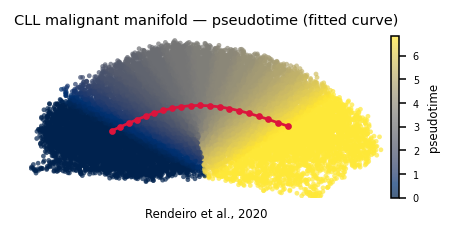

In [10]:
# map fitted node coords into the linear layout via the same rigid transform used for cells
xy_umap = adata.obsm['X_umap']; xy_lin = adata.obsm['X_umap_lin']
# solve linear map (rotation+flip) from X_umap -> X_umap_lin using least squares on centered coords
Ac = xy_umap - xy_umap.mean(0); Bc = xy_lin - xy_lin.mean(0)
M,_,_,_ = np.linalg.lstsq(Ac, Bc, rcond=None)
F = np.asarray(adata.uns['graph']['F']).T            # nodes x 2 (in X_umap space)
F_lin = (F - xy_umap.mean(0)) @ M + xy_lin.mean(0)
Bmat = np.asarray(adata.uns['graph']['B']); ii, jj = np.where(np.triu(Bmat>0))
xl = xy_lin
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sca = ax.scatter(xl[:,0], xl[:,1], c=t, cmap='cividis', s=6, alpha=.7, linewidths=0)
for a,b in zip(ii,jj):
    ax.plot([F_lin[a,0],F_lin[b,0]],[F_lin[a,1],F_lin[b,1]], '-', color='crimson', lw=1.4, zorder=5)
ax.scatter(F_lin[:,0], F_lin[:,1], c='crimson', s=6, zorder=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py); ax.axis('off')
ax.set_title('CLL malignant manifold — pseudotime (fitted curve)', size=7.5)
ax.text(.5,-.12,'Rendeiro et al., 2020', ha='center', transform=ax.transAxes, size=6)
cb = fig.colorbar(sca, ax=ax, fraction=0.046, pad=0.02); cb.ax.tick_params(labelsize=5); cb.set_label('pseudotime', size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight'); plt.show()
print('saved manifold.pdf with fitted curve edges')

### Save manifold

In [11]:
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
if 'graph' in adata.uns:
    gg = adata.uns['graph']
    adata.uns['graph'] = {k:(np.asarray(v) if k in ('B','F','R') else v) for k,v in gg.items()
                          if k not in ('Edges','pp_info','pp_seg') or True}
    # keep only serializable arrays; drop the raw ElPiGraph Edges list
    if 'Edges' in adata.uns['graph']: del adata.uns['graph']['Edges']
try:
    adata.write(os.path.join(pth_out, 'manifold.h5ad'))
except Exception as e:
    # fallback: stash graph arrays in obsm/uns-safe forms
    B = np.asarray(adata.uns['graph']['B']); F = np.asarray(adata.uns['graph']['F'])
    adata.uns['graph'] = {'B':B, 'F':F}
    adata.write(os.path.join(pth_out, 'manifold.h5ad'))
print('saved manifold.h5ad', adata.shape)

saved manifold.h5ad (18490, 14889)
